In [1]:
# =============================================================================
# CELL 1: IMPORTS AND SETUP
# =============================================================================
import pandas as pd
import numpy as np
import pyodbc
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

pd.set_option('display.max_columns', 100)
pd.set_option('display.min_rows', 50)

def run_sql(query):
    with pyodbc.connect("DSN=Redshift_prod_new") as conn:
        warnings.filterwarnings("ignore", category=UserWarning)
        df = pd.read_sql_query(sql=query, con=conn)
        warnings.filterwarnings("default", category=UserWarning)
    return df

with pyodbc.connect("DSN=Redshift_prod_new") as conn:
    conn.cursor().execute("SELECT 1").fetchone()
print("ODBC connection OK")

ODBC connection OK


In [2]:
# =============================================================================
# CELL 2: FETCH ALL DATA SOURCES
# =============================================================================

# --- RAGU individual inputs (gross loss notebook) ---
ragu_df = run_sql("""
    SELECT r.account_number, r.lob, r.book_date,
           r.model_score, r.gross_loss_impact, r.gross_loss_ragu,
           r.ltv, r.apr, r.amt_financed
    FROM sandbox.gl_ragu_individual r
    WHERE r.gross_loss_ragu IS NOT NULL
""")
ragu_df['book_date'] = pd.to_datetime(ragu_df['book_date'])
print(f"RAGU rows: {len(ragu_df):,}")

# --- Contract term (for loss_multiplier derivation) ---
term_df = run_sql("""
    SELECT account_number, con_term
    FROM edwnpi.los_deal_current_fact
    WHERE con_term IS NOT NULL
""")
print(f"Term rows: {len(term_df):,}")

# --- Recovery model predictions ---
recovery_df = run_sql("""
    SELECT account_number
         , lob
         , con_date AS book_date
         , CASE
               WHEN lob IN ('KMX', 'ENT', 'FLD')
                   THEN 0.15 * (pred_t0_adj_impound * (1 - pred_depr_rate_std_current) ^ 2.3)
                      + 0.85 * (pred_t0_adj_no_impound * (1 - pred_depr_rate_std_current) ^ 2.3)
               ELSE 0.15 * (pred_t0_adj_impound * (1 - pred_depr_rate_std_current) ^ 2)
                  + 0.85 * (pred_t0_adj_no_impound * (1 - pred_depr_rate_std_current) ^ 2)
           END AS new_recovery_multiplier
    FROM sandbox.rds_rec_model_originations rec
    LEFT JOIN edwnpi.date_dim AS dd
              ON rec.con_date = dd.calendar_date
""")
recovery_df['book_date'] = pd.to_datetime(recovery_df['book_date'])
print(f"Recovery model rows: {len(recovery_df):,}")

# --- Actual chargeoff outcomes ---
actuals_df = run_sql("""
    WITH all_accounts AS (
        SELECT account_number,
               sp_book_date_quarter_vintage,
               MAX(proceeds) AS proceeds
        FROM edwnpi.svc_master_monthend
        WHERE sp_book_date_quarter_vintage >= '2020 Q1'
        GROUP BY 1, 2
    ),
    chargeoffs AS (
        SELECT account_number,
               sp_book_date_quarter_vintage,
               MAX(gross_loss_amt) AS gross_loss_amt,
               MAX(net_loss_amt) AS net_loss_amt
        FROM edwnpi.svc_master_monthend
        WHERE sp_book_date_quarter_vintage >= '2020 Q1'
          AND account_life_cycle = 'CHARGEOFF'
        GROUP BY 1, 2
    )
    SELECT a.account_number,
           a.sp_book_date_quarter_vintage AS vintage,
           a.proceeds,
           COALESCE(co.gross_loss_amt, 0) AS gross_loss_amt,
           COALESCE(co.net_loss_amt, 0) AS net_loss_amt,
           CASE WHEN co.account_number IS NOT NULL THEN 1 ELSE 0 END AS is_chargeoff
    FROM all_accounts a
    LEFT JOIN chargeoffs co
        ON a.account_number = co.account_number
       AND a.sp_book_date_quarter_vintage = co.sp_book_date_quarter_vintage
""")
print(f"Actuals rows: {len(actuals_df):,}")
print(f"Chargeoff rate: {actuals_df['is_chargeoff'].mean():.4f}")

RAGU rows: 840,745
Term rows: 1,608,676
Recovery model rows: 1,250,850
Actuals rows: 970,771
Chargeoff rate: 0.3437


In [3]:
# =============================================================================
# CELL 3: MERGE ALL DATASETS AND DERIVE COLUMNS
# =============================================================================

V1_UL = 0.5
V1_UL_TO_MS = 0.027
MATURITY_CUTOFF = '2023-12-31'
LTV_MIN, LTV_MAX = 1.00, 2.00

# --- Merge RAGU with term data ---
ragu_with_term = ragu_df.merge(
    term_df[['account_number', 'con_term']].drop_duplicates(
        subset='account_number', keep='first'),
    on='account_number', how='left'
)

# --- Deduplicate recovery multiplier per account ---
nr = recovery_df[['account_number', 'new_recovery_multiplier']].drop_duplicates(
    subset='account_number', keep='first'
)

# --- Merge all sources ---
merged = ragu_with_term.merge(
    actuals_df[['account_number', 'vintage', 'proceeds', 'gross_loss_amt',
                'net_loss_amt', 'is_chargeoff']],
    on='account_number', how='inner'
).merge(
    nr, on='account_number', how='inner'
)

print(f"Pre-filter merged rows: {len(merged):,}")
print(f"Book date range: {merged['book_date'].min()} to {merged['book_date'].max()}")

# --- Maturity filter ---
merged = merged[merged['book_date'] <= MATURITY_CUTOFF].copy()
print(f"\nAfter maturity filter (<= {MATURITY_CUTOFF}): {len(merged):,} rows")
print(f"  Chargeoffs: {merged['is_chargeoff'].sum():,} ({merged['is_chargeoff'].mean():.1%})")

# --- Derive observed rates ---
merged['gross_loss_pct'] = merged['gross_loss_amt'] / merged['proceeds']
merged['cnl_pct'] = merged['net_loss_amt'] / merged['proceeds']
merged['recovery_pct'] = merged['gross_loss_pct'] - merged['cnl_pct']

# --- Back-derive loss_multiplier from V1 formula ---
merged['loss_multiplier'] = 1 - merged['gross_loss_impact'] * V1_UL_TO_MS / V1_UL

# --- Summary ---
print(f"\n--- Observed rate summary (all loans) ---")
for col in ['gross_loss_pct', 'cnl_pct', 'recovery_pct']:
    print(f"  {col:>20s}: mean={merged[col].mean():.4f}  std={merged[col].std():.4f}")

co = merged[merged['is_chargeoff'] == 1].copy()
print(f"\n--- Observed rate summary (chargeoffs only) ---")
for col in ['gross_loss_pct', 'cnl_pct', 'recovery_pct']:
    print(f"  {col:>20s}: mean={co[col].mean():.4f}  std={co[col].std():.4f}")

print(f"\nChargeoff population: {len(co):,}")
print(f"Chargeoffs with LTV in [100%, 200%): "
      f"{((co['ltv'] >= LTV_MIN) & (co['ltv'] < LTV_MAX)).sum():,}")

Pre-filter merged rows: 839,333
Book date range: 2020-01-02 00:00:00 to 2026-09-30 00:00:00

After maturity filter (<= 2023-12-31): 449,826 rows
  Chargeoffs: 232,037 (51.6%)

--- Observed rate summary (all loans) ---
        gross_loss_pct: mean=0.4224  std=0.4469
               cnl_pct: mean=0.3416  std=0.3951
          recovery_pct: mean=0.0808  std=0.1882

--- Observed rate summary (chargeoffs only) ---
        gross_loss_pct: mean=0.8189  std=0.2501
               cnl_pct: mean=0.6623  std=0.3004
          recovery_pct: mean=0.1566  std=0.2382

Chargeoff population: 232,037
Chargeoffs with LTV in [100%, 200%): 149,126


In [4]:
# =============================================================================
# CELL 4: INCREMENTAL R-SQUARED COMPUTATION FOR ALL THREE PANELS
# =============================================================================

def compute_incremental_r2(df, target_col, steps):
    """Compute incremental R2 for a sequence of stepwise OLS models.

    Parameters
    ----------
    df : DataFrame with all required columns.
    target_col : name of the observed target column.
    steps : list of (label, [col1, col2, ...]) tuples.

    Returns
    -------
    labels, incremental_r2, cumulative_r2 : lists of step labels,
        incremental R2 values, and cumulative R2 values.
    """
    required_cols = set()
    for _, cols in steps:
        required_cols.update(cols)
    required_cols.add(target_col)

    valid = df.dropna(subset=list(required_cols)).copy()
    y = valid[target_col].values

    labels = []
    incremental = []
    cumulative = []
    prev_r2 = 0.0

    for label, cols in steps:
        X = valid[cols].values
        lr = LinearRegression().fit(X, y)
        r2 = r2_score(y, lr.predict(X))
        n, k = len(y), X.shape[1]
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
        delta = r2 - prev_r2
        labels.append(label)
        incremental.append(delta)
        cumulative.append(r2)
        prev_r2 = r2

    return labels, incremental, cumulative, len(valid)


# =========================================================================
# Universal step ordering (same for all three targets)
# =========================================================================
universal_steps = [
    ('Model Score',        ['model_score']),
    ('+ Loss Multiplier',  ['model_score', 'loss_multiplier']),
    ('+ APR',              ['model_score', 'loss_multiplier', 'apr']),
    ('+ Recovery (R)',     ['model_score', 'loss_multiplier', 'apr',
                            'new_recovery_multiplier']),
    ('+ LTV',             ['model_score', 'loss_multiplier', 'apr',
                            'new_recovery_multiplier', 'ltv']),
]

step_labels = [s[0] for s in universal_steps]


# =========================================================================
# PANEL 1: Gross Loss (all loans)
# =========================================================================
gl_labels, gl_incr, gl_cum, gl_n = compute_incremental_r2(
    merged, 'gross_loss_pct', universal_steps
)

print("=" * 80)
print("PANEL 1: GROSS LOSS  (target = gross_loss_pct, all loans)")
print("=" * 80)
print(f"Population: {gl_n:,} loans\n")
print(f"{'Step':<25} {'Cumulative R²':>15} {'Incremental R²':>18}")
print("-" * 60)
for lbl, inc, cum in zip(gl_labels, gl_incr, gl_cum):
    print(f"  {lbl:<23} {cum:>15.5f} {inc:>+18.5f}")


# =========================================================================
# PANEL 2: Recovery (chargeoffs only, LTV in [100%, 200%))
# =========================================================================
co_ltv = merged[
    (merged['is_chargeoff'] == 1) &
    (merged['ltv'] >= LTV_MIN) &
    (merged['ltv'] < LTV_MAX)
].copy()

rec_labels, rec_incr, rec_cum, rec_n = compute_incremental_r2(
    co_ltv, 'recovery_pct', universal_steps
)

print(f"\n{'=' * 80}")
print("PANEL 2: RECOVERY  (target = recovery_pct, chargeoffs with LTV in [100%, 200%))")
print("=" * 80)
print(f"Population: {rec_n:,} chargeoffs\n")
print(f"{'Step':<25} {'Cumulative R²':>15} {'Incremental R²':>18}")
print("-" * 60)
for lbl, inc, cum in zip(rec_labels, rec_incr, rec_cum):
    print(f"  {lbl:<23} {cum:>15.5f} {inc:>+18.5f}")


# =========================================================================
# PANEL 3: Net Loss (all loans)
# =========================================================================
nl_labels, nl_incr, nl_cum, nl_n = compute_incremental_r2(
    merged, 'cnl_pct', universal_steps
)

print(f"\n{'=' * 80}")
print("PANEL 3: NET LOSS  (target = cnl_pct, all loans)")
print("=" * 80)
print(f"Population: {nl_n:,} loans\n")
print(f"{'Step':<25} {'Cumulative R²':>15} {'Incremental R²':>18}")
print("-" * 60)
for lbl, inc, cum in zip(nl_labels, nl_incr, nl_cum):
    print(f"  {lbl:<23} {cum:>15.5f} {inc:>+18.5f}")

PANEL 1: GROSS LOSS  (target = gross_loss_pct, all loans)
Population: 389,812 loans

Step                        Cumulative R²     Incremental R²
------------------------------------------------------------
  Model Score                     0.07639           +0.07639
  + Loss Multiplier               0.08130           +0.00491
  + APR                           0.08674           +0.00544
  + Recovery (R)                  0.08719           +0.00045
  + LTV                           0.08728           +0.00009

PANEL 2: RECOVERY  (target = recovery_pct, chargeoffs with LTV in [100%, 200%))
Population: 149,042 chargeoffs

Step                        Cumulative R²     Incremental R²
------------------------------------------------------------
  Model Score                     0.00014           +0.00014
  + Loss Multiplier               0.00121           +0.00108
  + APR                           0.00439           +0.00318
  + Recovery (R)                  0.07155           +0.06716
  + LTV  

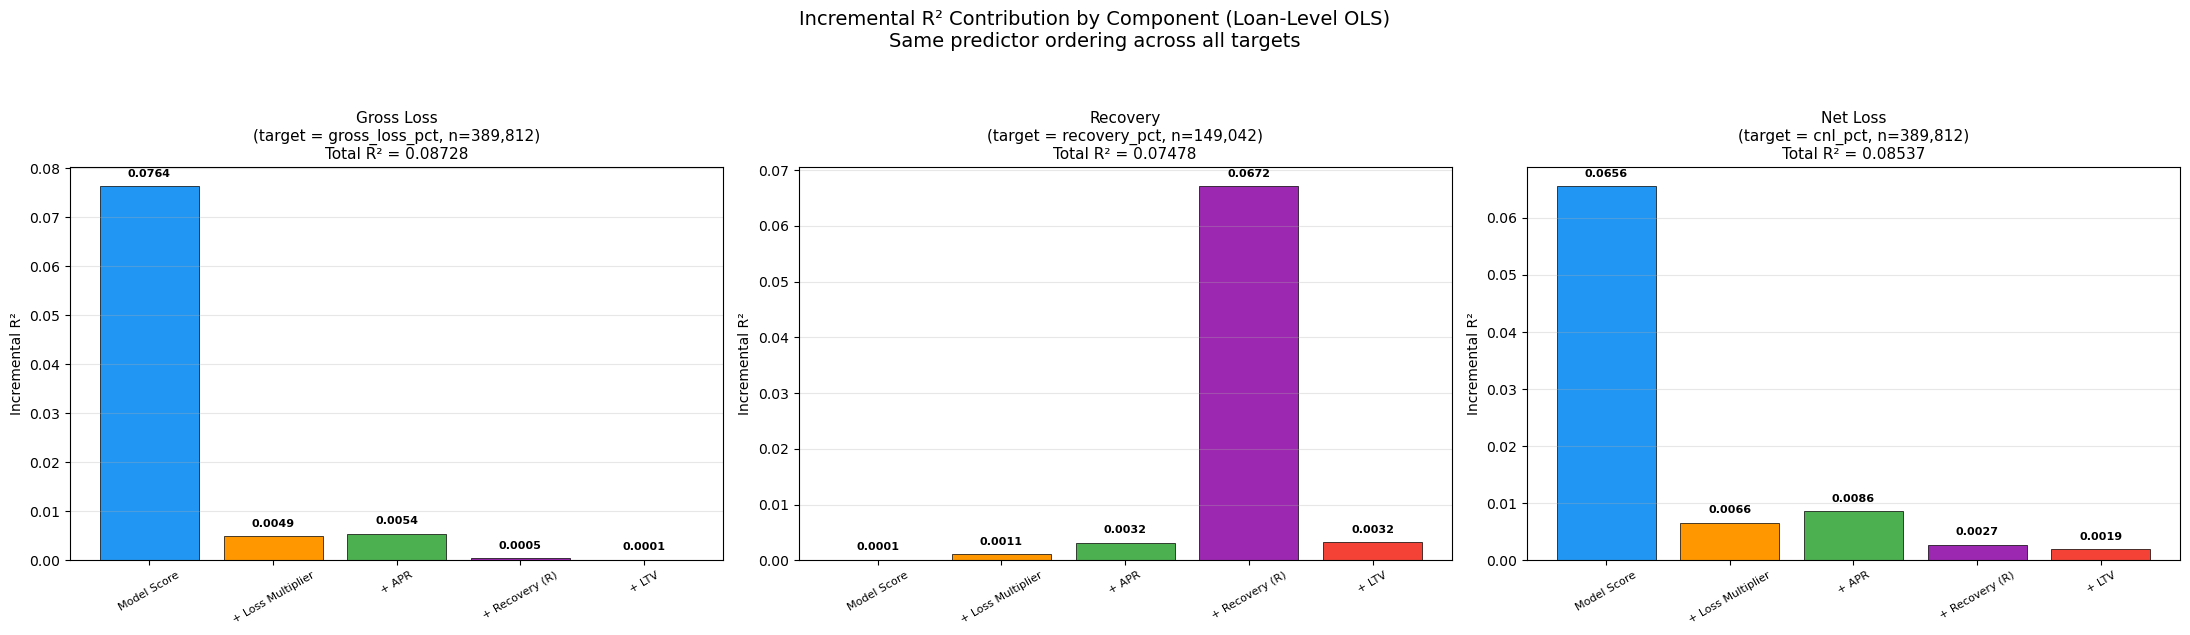

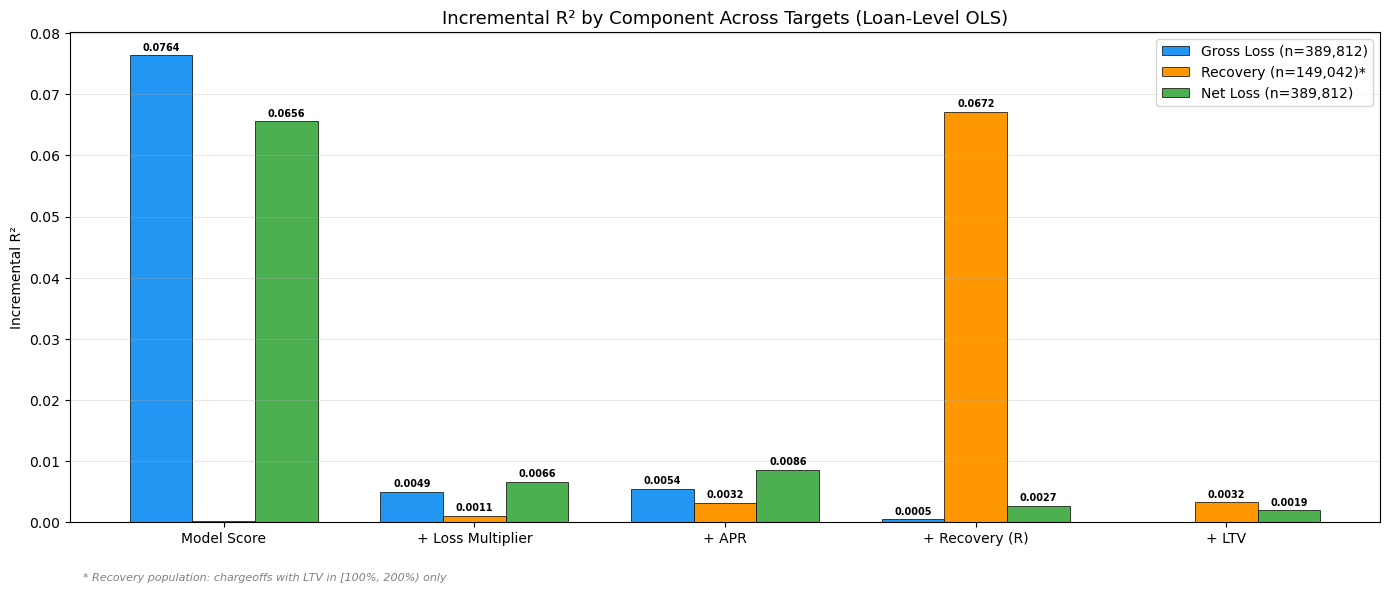

In [5]:
# =============================================================================
# CELL 5: INCREMENTAL R-SQUARED VISUALIZATIONS
# =============================================================================

COLOR_PALETTE = ['#2196F3', '#FF9800', '#4CAF50', '#9C27B0', '#F44336']

# =========================================================================
# FIGURE 1: Three-panel incremental R2 (by target)
# =========================================================================
panels = [
    {
        'title': f'Gross Loss\n(target = gross_loss_pct, n={gl_n:,})',
        'labels': gl_labels,
        'values': gl_incr,
        'cumulative': gl_cum,
    },
    {
        'title': f'Recovery\n(target = recovery_pct, n={rec_n:,})',
        'labels': rec_labels,
        'values': rec_incr,
        'cumulative': rec_cum,
    },
    {
        'title': f'Net Loss\n(target = cnl_pct, n={nl_n:,})',
        'labels': nl_labels,
        'values': nl_incr,
        'cumulative': nl_cum,
    },
]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, panel in zip(axes, panels):
    n_bars = len(panel['labels'])
    colors = COLOR_PALETTE[:n_bars]
    bars = ax.bar(panel['labels'], panel['values'], color=colors,
                  edgecolor='black', linewidth=0.5)

    y_max = max(panel['values'])
    for bar, val in zip(bars, panel['values']):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + y_max * 0.02,
                f'{val:.4f}', ha='center', va='bottom', fontsize=8,
                fontweight='bold')

    total_r2 = panel['cumulative'][-1]
    ax.set_title(f"{panel['title']}\nTotal R\u00b2 = {total_r2:.5f}", fontsize=11)
    ax.set_ylabel('Incremental R\u00b2')
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='x', rotation=30, labelsize=8)

plt.suptitle('Incremental R\u00b2 Contribution by Component (Loan-Level OLS)\n'
             'Same predictor ordering across all targets',
             fontsize=14, y=1.05)
plt.tight_layout()
plt.savefig('net_loss_incremental_r2_by_target.png', dpi=150, bbox_inches='tight')
plt.show()


# =========================================================================
# FIGURE 2: Grouped bar chart (by component)
# =========================================================================
x = np.arange(len(step_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

bars_gl  = ax.bar(x - width, gl_incr,  width, label=f'Gross Loss (n={gl_n:,})',
                  color='#2196F3', edgecolor='black', linewidth=0.5)
bars_rec = ax.bar(x,         rec_incr, width, label=f'Recovery (n={rec_n:,})*',
                  color='#FF9800', edgecolor='black', linewidth=0.5)
bars_nl  = ax.bar(x + width, nl_incr,  width, label=f'Net Loss (n={nl_n:,})',
                  color='#4CAF50', edgecolor='black', linewidth=0.5)

for bars in [bars_gl, bars_rec, bars_nl]:
    for bar in bars:
        h = bar.get_height()
        if h > 0.0002:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.0005,
                    f'{h:.4f}', ha='center', va='bottom', fontsize=7,
                    fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(step_labels, fontsize=10)
ax.set_ylabel('Incremental R\u00b2')
ax.set_title('Incremental R\u00b2 by Component Across Targets (Loan-Level OLS)',
             fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.annotate('* Recovery population: chargeoffs with LTV in [100%, 200%) only',
            xy=(0.01, -0.12), xycoords='axes fraction', fontsize=8,
            fontstyle='italic', color='gray')

plt.tight_layout()
plt.savefig('net_loss_incremental_r2_by_component.png', dpi=150, bbox_inches='tight')
plt.show()